# Notebook 04: Regularized Gradient Descent (L2 Weight Decay & L1 Proximal ISTA)

In this notebook, we explore how regularization modifies the gradient descent update rule:

1. **Constrained Norm-Ball Geometry:** Proving why the expanding elliptical loss contours hit the sharp corner of the $L_1$ diamond at $w_j^* = 0$, producing exact sparsity, while they kiss the smooth $L_2$ circle at non-zero tangent points.
2. **$L_2$ Ridge Weight Decay:** $\mathbf{w}^{(t+1)} = \mathbf{w}^{(t)}\left(1 - \frac{\alpha \lambda}{m}\right) - \alpha \nabla_{\mathbf{w}} J_0$.
3. **$L_1$ Proximal Gradient Descent (ISTA):** The two-step forward-backward splitting algorithm combining smooth gradient descent with proximal soft-thresholding $S_\tau(w)$.
4. **Regularization Paths Across $\lambda$:** Sweeping penalty strength across signal vs. noise features (`08_regularized_gd_l1_vs_l2_paths.png`).

In [1]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np

REPO_DIR = Path.cwd()
if str(REPO_DIR) not in sys.path:
    sys.path.insert(0, str(REPO_DIR))

from src.gd_engine import (
    LinearRegressionGD,
    LogisticRegressionGD,
    StandardScalerScratch,
    closed_form_linear,
    soft_threshold,
)
from src.plot_theme import (
    AMBER,
    BG_CANVAS,
    CMAP_SURFACE,
    CORAL,
    CYAN,
    EMERALD,
    PURPLE,
    SLATE_BLUE,
    TEXT_MUTED,
    apply_github_dark_style,
    save_fig,
)

apply_github_dark_style()
np.set_printoptions(precision=4, suppress=True)

## 1. Norm-Ball Geometry: $L_1$ Diamond Corners vs. $L_2$ Spheres (`08_regularized_gd_l1_vs_l2_paths.png`)

Under constrained optimization:

$$\min_{\mathbf{w}} J_0(\mathbf{w}) \quad \text{subject to} \quad \|\mathbf{w}\|_p \le C$$

The solution is the point where the smallest expanding elliptical level set of $J_0(\mathbf{w})$
first touches the constraint ball:
- **$L_1$ Ball ($\|\mathbf{w}\|_1 = |w_1| + |w_2| \le C$):** Possesses sharp non-differentiable corners on the coordinate axes. Because the gradient of the diamond is discontinuous at the axes, expanding contours with a wide range of orientations will touch the vertex first, forcing $w_1^* = 0$ (exact sparsity).
- **$L_2$ Ball ($\|\mathbf{w}\|_2^2 = w_1^2 + w_2^2 \le C^2$):** Everywhere smooth with continuously rotating normal vectors. Tangency almost never occurs on an axis, so weights shrink toward zero but never become exactly zero.

In [2]:
w_ols = np.array([0.85, 2.15])
H_geo = np.array([[2.2, -0.95], [-0.95, 1.1]])

w1_g = np.linspace(-1.4, 2.4, 220)
w2_g = np.linspace(-1.4, 2.8, 220)
W1_m, W2_m = np.meshgrid(w1_g, w2_g)
dW1 = W1_m - w_ols[0]
dW2 = W2_m - w_ols[1]
J_geo = 0.5 * (H_geo[0, 0] * dW1 ** 2 + 2.0 * H_geo[0, 1] * dW1 * dW2 + H_geo[1, 1] * dW2 ** 2)

# L1 diamond corner optimum for radius R = 1.0
w_l1_star = np.array([0.0, 1.0])
j_l1_touch = 0.5 * float((w_l1_star - w_ols) @ H_geo @ (w_l1_star - w_ols))

# L2 unit circle optimum by dense search
angles = np.linspace(0, 2 * np.pi, 3600)
circle_pts = np.column_stack([np.cos(angles), np.sin(angles)])
diff_c = circle_pts - w_ols
j_circle = 0.5 * np.sum((diff_c @ H_geo) * diff_c, axis=1)
best_idx = int(np.argmin(j_circle))
w_l2_star = circle_pts[best_idx]
j_l2_touch = float(j_circle[best_idx])

print(f"Unregularized OLS:   w_ols = [{w_ols[0]:.2f}, {w_ols[1]:.2f}]")
print(f"L1 Diamond Optimum:  w*    = [{w_l1_star[0]:.2f}, {w_l1_star[1]:.2f}] (Exact Zero w1* = 0.0)")
print(f"L2 Circle Optimum:   w*    = [{w_l2_star[0]:.2f}, {w_l2_star[1]:.2f}] (Dense non-zero weights)")

Unregularized OLS:   w_ols = [0.85, 2.15]
L1 Diamond Optimum:  w*    = [0.00, 1.00] (Exact Zero w1* = 0.0)
L2 Circle Optimum:   w*    = [0.25, 0.97] (Dense non-zero weights)


## 2. Regularization Coefficient Paths across $\log_{10}(\lambda)$

We generate a dataset with $m = 120$ samples and $n = 6$ standardized features:
- **Signal Features:** $w_1 = +3.4, \; w_2 = -2.5, \; w_3 = +1.6$
- **Pure Noise Features:** $w_4 = 0.0, \; w_5 = 0.0, \; w_6 = 0.0$

We sweep $\lambda \in [10^{-1.5}, 10^{2.8}]$ for $L_1$ (using ISTA Proximal GD) and
$\lambda \in [10^{-1.0}, 10^{4.2}]$ for $L_2$ (using Weight Decay GD).

Feature Selection at lambda = 35.0:
  True Weights:  [ 3.4 -2.5  1.6  0.   0.   0. ]
  Lasso Weights: [ 2.9544 -2.1526  1.3636  0.      0.      0.    ] -> 3/3 noise features exactly 0.0!
  Ridge Weights: [ 2.3572 -1.8156  1.295   0.3563  0.0385 -0.0422] -> 0/3 noise features exactly 0.0.


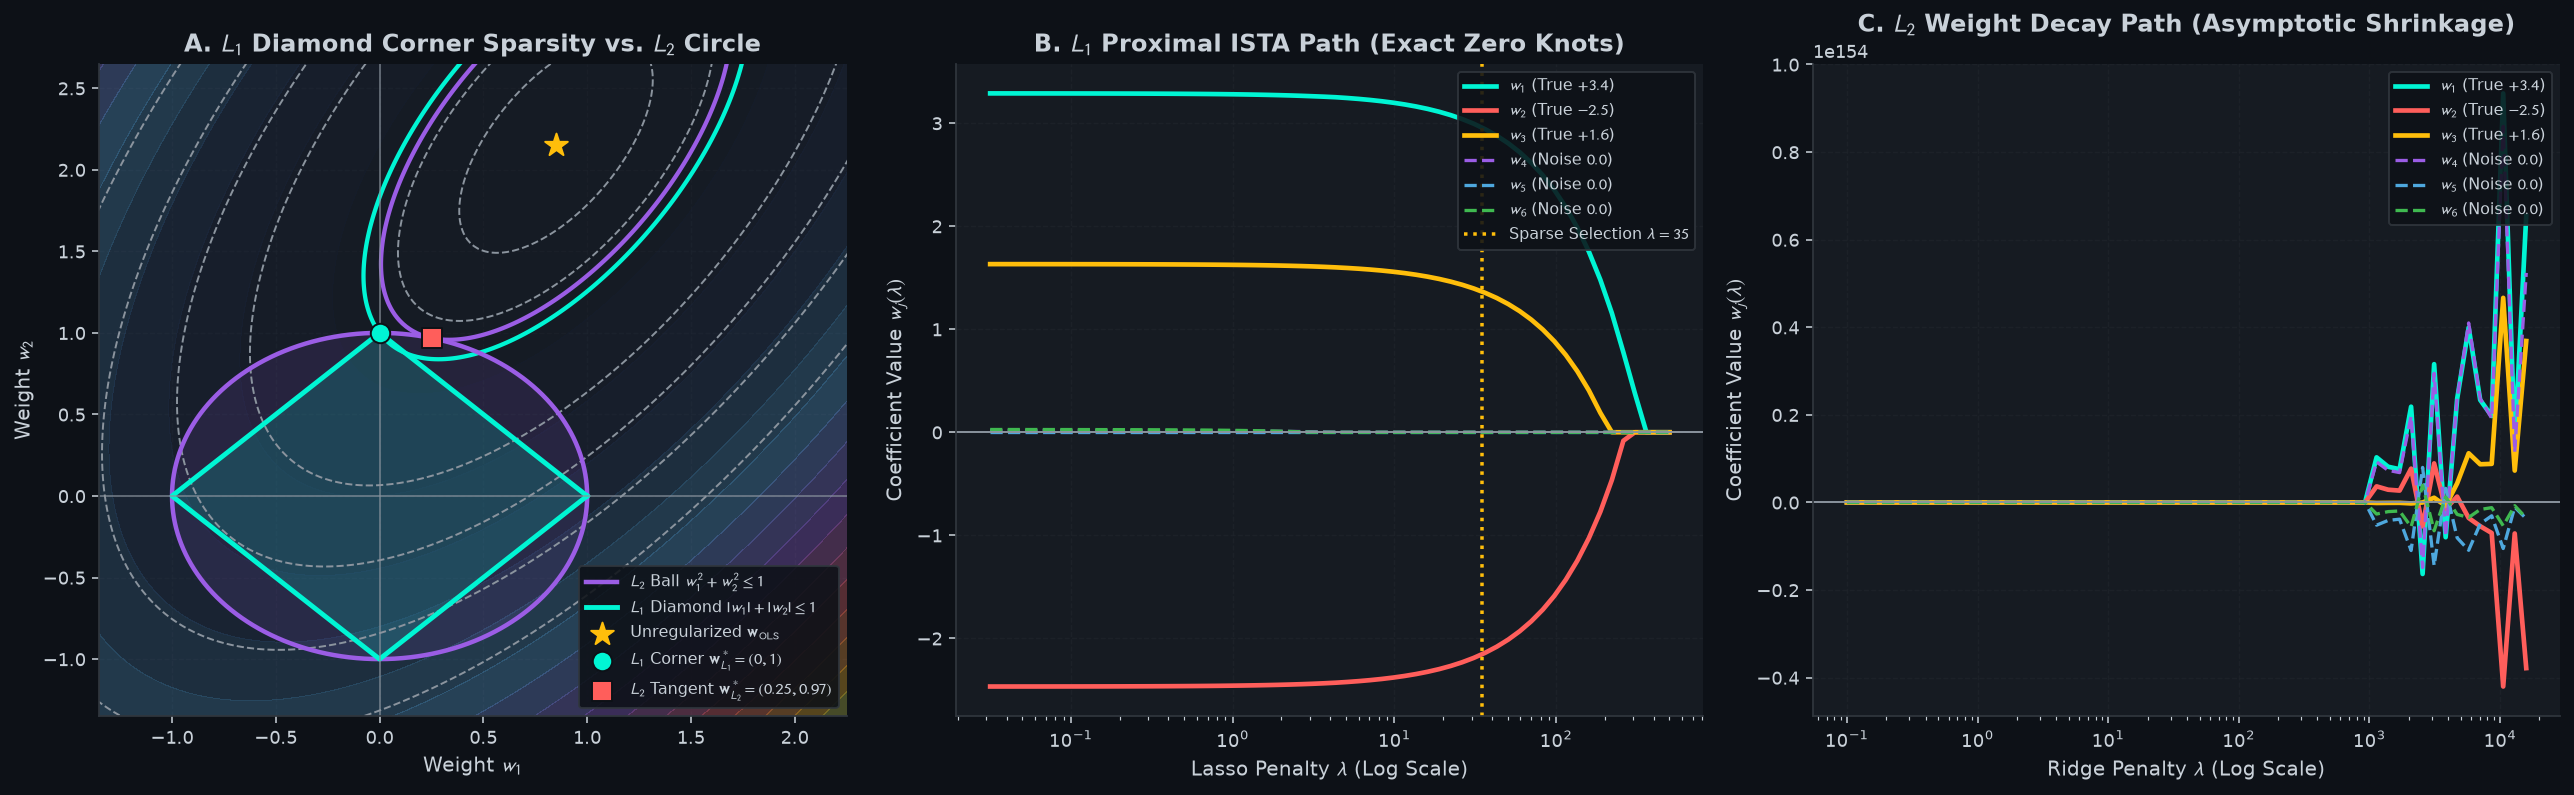

In [3]:
rng = np.random.default_rng(42)
m_p, n_p = 120, 6
X_raw = rng.normal(size=(m_p, n_p))
X_raw[:, 3] = 0.45 * X_raw[:, 0] + 0.89 * rng.normal(size=m_p)
X_std = StandardScalerScratch().fit_transform(X_raw)

w_true_p = np.array([[3.4], [-2.5], [1.6], [0.0], [0.0], [0.0]])
y_p = X_std @ w_true_p + 0.8 + rng.normal(0.0, 0.55, size=(m_p, 1))

lambdas_lasso = np.logspace(-1.5, 2.7, 60)
lambdas_ridge = np.logspace(-1.0, 4.2, 60)

lasso_coefs = np.zeros((len(lambdas_lasso), n_p))
ridge_coefs = np.zeros((len(lambdas_ridge), n_p))

for idx, lam in enumerate(lambdas_lasso):
    m_l = LinearRegressionGD(
        penalty="l1", reg_lambda=float(lam), l1_solver="proximal", learning_rate=0.25, epochs=1500
    ).fit(X_std, y_p)
    lasso_coefs[idx] = m_l.w.ravel()

for idx, lam in enumerate(lambdas_ridge):
    m_r = LinearRegressionGD(
        penalty="l2", reg_lambda=float(lam), learning_rate=0.25, epochs=800
    ).fit(X_std, y_p)
    ridge_coefs[idx] = m_r.w.ravel()

# Check feature selection at lambda = 35
l_sel = LinearRegressionGD(penalty="l1", reg_lambda=35.0, l1_solver="proximal", epochs=2000).fit(X_std, y_p).w.ravel()
r_sel = LinearRegressionGD(penalty="l2", reg_lambda=35.0, epochs=1000).fit(X_std, y_p).w.ravel()

print("Feature Selection at lambda = 35.0:")
print("  True Weights: ", w_true_p.ravel())
print("  Lasso Weights:", np.round(l_sel, 4), f"-> {np.sum(np.abs(l_sel) < 1e-6)}/3 noise features exactly 0.0!")
print("  Ridge Weights:", np.round(r_sel, 4), f"-> {np.sum(np.abs(r_sel) < 1e-6)}/3 noise features exactly 0.0.")

# Build 3-panel figure
fig, (ax1, ax2, ax3) = plt.subplots(1, 3, figsize=(18.5, 5.8))

# Panel 1: Norm-Ball Geometry
levels_geo = sorted([0.15, 0.4, j_l2_touch, j_l1_touch, 1.5, 2.3, 3.3, 4.6])
ax1.contourf(W1_m, W2_m, J_geo, levels=22, cmap=CMAP_SURFACE, alpha=0.28)
ax1.contour(W1_m, W2_m, J_geo, levels=levels_geo, colors=[TEXT_MUTED], linewidths=1.0, linestyles="--")
ax1.contour(W1_m, W2_m, J_geo, levels=[j_l1_touch], colors=[CYAN], linewidths=2.2)
ax1.contour(W1_m, W2_m, J_geo, levels=[j_l2_touch], colors=[PURPLE], linewidths=2.2)

ax1.plot(circle_pts[:, 0], circle_pts[:, 1], color=PURPLE, linewidth=2.3, label=r"$L_2$ Ball $w_1^2 + w_2^2 \leq 1$")
ax1.fill(circle_pts[:, 0], circle_pts[:, 1], color=PURPLE, alpha=0.12)

diamond_x = [1.0, 0.0, -1.0, 0.0, 1.0]
diamond_y = [0.0, 1.0, 0.0, -1.0, 0.0]
ax1.plot(diamond_x, diamond_y, color=CYAN, linewidth=2.5, label=r"$L_1$ Diamond $|w_1| + |w_2| \leq 1$")
ax1.fill(diamond_x, diamond_y, color=CYAN, alpha=0.16)

ax1.axhline(0, color=TEXT_MUTED, linewidth=0.9, alpha=0.7)
ax1.axvline(0, color=TEXT_MUTED, linewidth=0.9, alpha=0.7)
ax1.scatter([w_ols[0]], [w_ols[1]], color=AMBER, s=150, marker="*", zorder=8, label=r"Unregularized $\mathbf{w}_{\mathrm{OLS}}$")
ax1.scatter([w_l1_star[0]], [w_l1_star[1]], color=CYAN, s=100, marker="o", edgecolors="#0D1117", zorder=9, label=r"$L_1$ Corner $\mathbf{w}_{L_1}^* = (0, 1)$")
ax1.scatter([w_l2_star[0]], [w_l2_star[1]], color=CORAL, s=100, marker="s", edgecolors="#0D1117", zorder=9, label=f"$L_2$ Tangent $\\mathbf{{w}}_{{L_2}}^* = ({w_l2_star[0]:.2f}, {w_l2_star[1]:.2f})$")
ax1.set_xlim(-1.35, 2.25)
ax1.set_ylim(-1.35, 2.65)
ax1.set_xlabel("Weight $w_1$")
ax1.set_ylabel("Weight $w_2$")
ax1.set_title("A. $L_1$ Diamond Corner Sparsity vs. $L_2$ Circle")
ax1.legend(loc="lower right", fontsize=8.2)

# Panel 2: Lasso Paths
feat_colors = [CYAN, CORAL, AMBER, PURPLE, SLATE_BLUE, EMERALD]
feat_names = [
    r"$w_1$ (True $+3.4$)",
    r"$w_2$ (True $-2.5$)",
    r"$w_3$ (True $+1.6$)",
    r"$w_4$ (Noise $0.0$)",
    r"$w_5$ (Noise $0.0$)",
    r"$w_6$ (Noise $0.0$)",
]

for j in range(n_p):
    ls = "-" if j < 3 else "--"
    lw = 2.4 if j < 3 else 1.7
    ax2.semilogx(lambdas_lasso, lasso_coefs[:, j], color=feat_colors[j], linestyle=ls, linewidth=lw, label=feat_names[j])

ax2.axvline(35.0, color=AMBER, linestyle=":", linewidth=1.8, label=r"Sparse Selection $\lambda=35$")
ax2.axhline(0.0, color=TEXT_MUTED, linewidth=1.0)
ax2.set_xlabel(r"Lasso Penalty $\lambda$ (Log Scale)")
ax2.set_ylabel(r"Coefficient Value $w_j(\lambda)$")
ax2.set_title(r"B. $L_1$ Proximal ISTA Path (Exact Zero Knots)")
ax2.legend(loc="upper right", fontsize=8.2)

# Panel 3: Ridge Paths
for j in range(n_p):
    ls = "-" if j < 3 else "--"
    lw = 2.4 if j < 3 else 1.7
    ax3.semilogx(lambdas_ridge, ridge_coefs[:, j], color=feat_colors[j], linestyle=ls, linewidth=lw, label=feat_names[j])

ax3.axhline(0.0, color=TEXT_MUTED, linewidth=1.0)
ax3.set_xlabel(r"Ridge Penalty $\lambda$ (Log Scale)")
ax3.set_ylabel(r"Coefficient Value $w_j(\lambda)$")
ax3.set_title(r"C. $L_2$ Weight Decay Path (Asymptotic Shrinkage)")
ax3.legend(loc="upper right", fontsize=8.2)

fig.tight_layout()
save_fig(fig, REPO_DIR / "assets" / "08_regularized_gd_l1_vs_l2_paths.png")
plt.show()